# Otimização dos modelos de SOP com Algoritmo Genético e interpretação com LLM
### Tech Challenge, Fase 2 (Projeto 1)

Fabricio Geraldo Araujo

Este notebook continua o trabalho da Fase 1, em que construí um modelo de apoio à triagem da Síndrome dos Ovários Policísticos (SOP). Aqui eu faço três coisas:

1. otimizo os hiperparâmetros dos três modelos da Fase 1 com um algoritmo genético;
2. uso uma LLM para explicar cada previsão em linguagem simples para o médico;
3. registro tudo com logging e MLflow.

O algoritmo genético está em `src/ga.py` e a parte da LLM em `src/llm.py`, os dois com testes em `tests/`. A arquitetura está em `docs/arquitetura.md` e o relatório em `docs/relatorio_tecnico.md`.

**Para rodar:** siga o README. Os experimentos do AG levaram cerca de 2 horas, então deixei os resultados salvos em `outputs/experimentos/` e o notebook só carrega (`RODAR_EXPERIMENTOS = False`). Sem a chave do Groq no `.env`, ele roda normalmente e só pula as chamadas à LLM.

## 1. O problema

Na Fase 1 comparei Regressão Logística, Random Forest e KNN para identificar SOP a partir de 41 variáveis clínicas de 541 pacientes. Escolhi a Regressão Logística, com recall de 0,861, porque na triagem o erro mais grave é o falso negativo: a paciente que tem SOP e não é identificada.

Nenhum dos modelos teve ajuste de hiperparâmetros. No fim daquele projeto, deixei como próximos passos ajustar os hiperparâmetros, ajustar o limiar de decisão e monitorar o modelo. Esta fase faz o primeiro e o último, e acrescenta a explicação das previsões com LLM. O limiar ficou para depois.

## 2. Arquitetura

![Arquitetura da solução](../docs/arquitetura.png)

A ideia principal é que o algoritmo genético (`src/ga.py`) não sabe nada de machine learning. Ele recebe uma função que dá nota para cada combinação de hiperparâmetros e procura a melhor. Quem monta essa função, treinando o modelo e medindo o resultado, é o notebook. Assim o mesmo AG serve para os três modelos.

## Preparação do ambiente

Imports, caminhos do projeto e configuração do logging e do MLflow.

In [ ]:
# Se algum pacote faltar: pip install -r requirements.txt (na raiz do projeto)

import os, sys, json, time, logging, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Encontra a raiz do projeto (a pasta que tem src/ga.py), para conseguir importar os módulos
RAIZ = next(p for p in [Path.cwd().parent, Path.cwd(), Path.cwd().parent / "tech-challenge-fase2"]
            if (p / "src" / "ga.py").exists())
sys.path.insert(0, str(RAIZ))
from src import ga, llm      # ga = algoritmo genético, llm = integração com a LLM

# Lê a chave da API do arquivo .env
from dotenv import load_dotenv
load_dotenv(RAIZ / ".env")

SEED = 42   # mesma semente da Fase 1: resultados iguais a cada execução

# Pastas do projeto
DADOS = RAIZ / "datasets" / "PCOS_data_without_infertility.xlsx"
SAIDAS, LOGS = RAIZ / "outputs", RAIZ / "logs"
for pasta in (SAIDAS / "experimentos", LOGS):
    pasta.mkdir(parents=True, exist_ok=True)

# Os experimentos do AG levam cerca de 2 horas. Deixei salvos e aqui só carrego.
# True para rodar de novo os que estiverem faltando em outputs/experimentos/.
RODAR_EXPERIMENTOS = False
# Chama a LLM só para o que ainda não foi respondido. Sem chave no .env, pula.
GERAR_INTERPRETACOES = True

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 4)
print("raiz do projeto:", RAIZ)

raiz do projeto: /home/fabricio/ESTUDOS/FIAP/FASE 2/tech-challenge/tech-challenge-fase2


In [2]:
def logger_em_arquivo(nome, arquivo):
    """Faz o logger 'nome' gravar no 'arquivo' (sem duplicar se a célula rodar duas vezes)."""
    lg = logging.getLogger(nome)
    lg.setLevel(logging.INFO)
    ja_tem = any(isinstance(h, logging.FileHandler) and Path(h.baseFilename) == Path(arquivo).resolve()
                 for h in lg.handlers)
    if not ja_tem:
        h = logging.FileHandler(arquivo, encoding="utf-8")
        h.setFormatter(logging.Formatter("%(asctime)s | %(levelname)-7s | %(message)s"))
        lg.addHandler(h)
    lg.propagate = False
    return lg

# Cada módulo grava no seu próprio arquivo de log
logger_em_arquivo("src.ga", LOGS / "ga.log")     # uma linha por geração do AG
logger_em_arquivo("src.llm", LOGS / "llm.log")   # uma linha por chamada à LLM

# MLflow para registrar os experimentos. Uso SQLite porque o modo de pasta (mlruns) foi descontinuado.
os.environ.setdefault("MLFLOW_DISABLE_TELEMETRY", "true")
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
warnings.filterwarnings("ignore", message="IProgress not found")
import mlflow
for barulhento in ("mlflow", "alembic"):          # deixa a saída do notebook mais limpa
    logging.getLogger(barulhento).setLevel(logging.WARNING)
mlflow.set_tracking_uri(f"sqlite:///{RAIZ / 'mlflow.db'}")
mlflow.set_experiment("tech-challenge-fase2")
print("logs em", LOGS, "| MLflow em", RAIZ / "mlflow.db")

logs em /home/fabricio/ESTUDOS/FIAP/FASE 2/tech-challenge/tech-challenge-fase2/logs | MLflow em /home/fabricio/ESTUDOS/FIAP/FASE 2/tech-challenge/tech-challenge-fase2/mlflow.db


## 3. Carga e limpeza dos dados

A limpeza é a mesma da Fase 1, com uma diferença: não preencho mais os valores ausentes aqui. Isso passou para dentro do Pipeline.

In [3]:
from sklearn.model_selection import train_test_split

# Mesma aba da Fase 1, com os dados completos
df = pd.read_excel(DADOS, sheet_name="Full_new")

# Remove espaços extras nos nomes das colunas
df.columns = df.columns.str.strip()

# Remove os identificadores ("Sl. No", "Patient File No.") e a coluna vazia ("Unnamed: 44")
df = df.drop(columns=["Sl. No", "Patient File No.", "Unnamed: 44"], errors="ignore")

# Duas colunas de exame vieram como texto por erro de digitação; o que não converte vira NaN
for col in ["II    beta-HCG(mIU/mL)", "AMH(ng/mL)"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Diferente da Fase 1: NÃO preencho os ausentes aqui. Isso agora é feito dentro do Pipeline.

ALVO = "PCOS (Y/N)"
X, y = df.drop(columns=[ALVO]), df[ALVO]

# Mesma divisão da Fase 1 (80/20, estratificada, mesma semente): o teste é o mesmo
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)

print(f"{X.shape[0]} pacientes, {X.shape[1]} variáveis, {int(X.isna().sum().sum())} valores ausentes")
print(f"treino: {len(X_train)} ({int(y_train.sum())} com SOP) | teste: {len(X_test)} ({int(y_test.sum())} com SOP)")

541 pacientes, 41 variáveis, 4 valores ausentes
treino: 432 (141 com SOP) | teste: 109 (36 com SOP)


## 4. Como avaliar os modelos

### 4.1 Duas correções em relação à Fase 1

**Imputação dentro do Pipeline.** Na Fase 1, a mediana usada para preencher os ausentes foi calculada com o dataset inteiro, antes de separar treino e teste. Ou seja, o teste influenciou o treino. Agora o `SimpleImputer` fica dentro do Pipeline e só aprende com os dados de treino.

**Validação cruzada no treino.** O teste tem só 36 pacientes com SOP, então cada paciente vale quase 3 pontos de recall. Se o AG escolhesse olhando o teste, eu estaria otimizando o acaso. Por isso o AG usa a média de uma validação cruzada de 5 dobras no treino, e o teste só é usado uma vez, no final (seção 7).

### 4.2 A função fitness

Usei o **F2**, que é parecido com o F1, mas dá quatro vezes mais peso ao recall do que à precisão. Assim mantenho a prioridade da Fase 1 sem premiar um modelo que diz "SOP" para todo mundo.

In [4]:
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (make_scorer, fbeta_score, precision_score, recall_score, f1_score,
                             roc_auc_score, accuracy_score, confusion_matrix)

# Validação cruzada de 5 dobras, estratificada (cada dobra com ~33% de SOP).
# Embaralho com semente fixa para todos os indivíduos do AG serem avaliados nas mesmas dobras.
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# F2: o recall pesa 4 vezes mais que a precisão.
# zero_division=0 evita aviso quando um modelo não prevê nenhum positivo numa dobra.
F2 = make_scorer(fbeta_score, beta=2, zero_division=0)

# Métricas registradas em cada avaliação (só o F2 guia o AG)
METRICAS = {"f2": F2, "recall": "recall", "precisao": make_scorer(precision_score, zero_division=0),
            "f1": make_scorer(f1_score, zero_division=0), "auc": "roc_auc"}
NOMES = {"lr": "Regressão Logística", "rf": "Random Forest", "knn": "KNN"}


def montar_pipeline(modelo):
    """Imputação + padronização + modelo. Dentro do Pipeline, os dois primeiros só aprendem com o treino."""
    return Pipeline([("imputer", SimpleImputer(strategy="median")),
                     ("scaler", StandardScaler()),
                     ("modelo", modelo)])


def modelo_original(nome):
    """Os três modelos exatamente como foram usados na Fase 1."""
    return {"lr": LogisticRegression(max_iter=1000, random_state=SEED),
            "rf": RandomForestClassifier(random_state=SEED),
            "knn": KNeighborsClassifier(n_neighbors=5)}[nome]


def modelo_com(nome, params):
    """O modelo com os hiperparâmetros escolhidos pelo AG."""
    if nome == "lr":
        # liblinear aceita L1 e L2 (o AG escolhe pelo l1_ratio)
        return LogisticRegression(solver="liblinear", max_iter=1000, random_state=SEED, **params)
    if nome == "rf":
        # n_jobs=1 aqui porque o paralelismo já está na validação cruzada
        return RandomForestClassifier(random_state=SEED, n_jobs=1, **params)
    return KNeighborsClassifier(**params)


def avaliar_cv(pipeline):
    """Média e desvio de todas as métricas na validação cruzada (só no treino)."""
    r = cross_validate(pipeline, X_train, y_train, cv=CV, scoring=METRICAS, n_jobs=-1)
    return {m: (r[f"test_{m}"].mean(), r[f"test_{m}"].std()) for m in METRICAS}


def fitness(nome):
    """Devolve a função que o AG usa para dar nota a cada indivíduo: a média do F2 na validação cruzada."""
    def avaliar(params):
        pipe = montar_pipeline(modelo_com(nome, params))
        return cross_val_score(pipe, X_train, y_train, cv=CV, scoring=F2, n_jobs=-1).mean()
    return avaliar

### 4.3 Os modelos originais no protocolo novo

Na tabela abaixo estão os números da Fase 1 como foram entregues, os mesmos modelos avaliados na validação cruzada, e um modelo "degenerado" que diz que todas as pacientes têm SOP.

In [5]:
def f_beta(p, r, beta=2):
    """F-beta a partir da precisão (p) e do recall (r)."""
    return (1 + beta**2) * p * r / (beta**2 * p + r)

# Números do notebook da Fase 1 no teste: (precisão, recall, F1, AUC)
FASE1 = {"lr": (0.816, 0.861, 0.838, 0.951), "rf": (0.903, 0.778, 0.836, 0.948), "knn": (0.963, 0.722, 0.825, 0.937)}

linhas = []

# 1) Fase 1 como foi entregue
for nome, (p, r, f1, auc) in FASE1.items():
    linhas.append({"modelo": NOMES[nome], "protocolo": "Fase 1, teste", "F2": f_beta(p, r), "recall": r,
                   "precisão": p, "F1": f1, "AUC": auc})

# 2) Os mesmos modelos, agora na validação cruzada
baseline_cv = {}
for nome in NOMES:
    baseline_cv[nome] = avaliar_cv(montar_pipeline(modelo_original(nome)))
    m = baseline_cv[nome]
    linhas.append({"modelo": NOMES[nome], "protocolo": "novo, CV 5 dobras", "F2": m["f2"][0], "recall": m["recall"][0],
                   "precisão": m["precisao"][0], "F1": m["f1"][0], "AUC": m["auc"][0], "desvio F2": m["f2"][1]})

# 3) Modelo "degenerado": diz que todas as pacientes têm SOP (serve de piso para a fitness)
degenerado = avaliar_cv(montar_pipeline(DummyClassifier(strategy="constant", constant=1)))
linhas.append({"modelo": "Degenerado: todas têm SOP", "protocolo": "novo, CV 5 dobras", "F2": degenerado["f2"][0],
               "recall": degenerado["recall"][0], "precisão": degenerado["precisao"][0], "F1": degenerado["f1"][0],
               "AUC": degenerado["auc"][0], "desvio F2": degenerado["f2"][1]})

tabela_baseline = pd.DataFrame(linhas)
tabela_baseline.to_csv(SAIDAS / "baseline.csv", index=False)
tabela_baseline.round(3)

,modelo,protocolo,F2,recall,precisão,F1,AUC,desvio F2
0,Regressão Logística,"Fase 1, teste",0.852,0.861,0.816,0.838,0.951,NaN
1,Random Forest,"Fase 1, teste",0.800,0.778,0.903,0.836,0.948,NaN
2,KNN,"Fase 1, teste",0.760,0.722,0.963,0.825,0.937,NaN
3,Regressão Logística,"novo, CV 5 dobras",0.790,0.787,0.810,0.796,0.934,0.056
4,Random Forest,"novo, CV 5 dobras",0.787,0.767,0.899,0.823,0.953,0.061
5,KNN,"novo, CV 5 dobras",0.725,0.696,0.890,0.776,0.913,0.044
6,Degenerado: todas têm SOP,"novo, CV 5 dobras",0.708,1.000,0.326,0.492,0.500,0.004


**Leitura:** na validação cruzada os números ficam mais baixos que no teste da Fase 1 (F2 de 0,790 contra 0,852 na Regressão Logística). O modelo não piorou; a validação cruzada é uma média de 5 divisões e costuma ser mais conservadora. Por isso só comparo números medidos do mesmo jeito.

### 4.4 Por que não usar o recall com peso

Pensei em usar algo como 0,7 × recall + 0,3 × F1. Fazendo a conta com a tabela acima, o modelo degenerado tiraria 0,848, mais que o Random Forest (0,784) e o KNN (0,720). O AG seria puxado justamente para o modelo inútil. Com o F2 o degenerado fica em 0,708, abaixo dos três.

Então a fitness do AG é a média do F2 na validação cruzada. As outras métricas eu registro, mas não uso para decidir.

## 5. O algoritmo genético

### 5.1 Codificação

Cada indivíduo é uma combinação de hiperparâmetros de um modelo. Como os hiperparâmetros são de tipos diferentes (número real, inteiro, categoria), usei a codificação híbrida vista em aula.

Dois detalhes: o `C` da Regressão Logística é guardado como expoente (`C = 10 ** gene`), porque o efeito dele é multiplicativo; e a penalidade L1/L2 virou `l1_ratio`, porque o parâmetro `penalty` foi descontinuado no scikit-learn 1.8.

In [6]:
# Espaço de busca de cada modelo (definido em src/ga.py): gene, tipo e faixa de valores
linhas = []
for nome, espaco in ga.ESPACOS.items():
    for gene, (tipo, *args) in espaco.items():
        if tipo == "categorico":
            faixa = ", ".join(map(str, args[0]))
        elif tipo == "log10":
            faixa = f"10^{args[0]:g} a 10^{args[1]:g}"      # o gene guarda o expoente
        else:
            faixa = f"{args[0]} a {args[1]}"
        linhas.append({"modelo": NOMES[nome], "gene": gene, "tipo": tipo, "faixa": faixa})
pd.DataFrame(linhas)

,modelo,gene,tipo,faixa
0,Regressão Logística,C,log10,10^-3 a 10^2
1,Regressão Logística,l1_ratio,categorico,"0.0, 1.0"
2,Regressão Logística,class_weight,categorico,"None, balanced"
3,Random Forest,n_estimators,inteiro,50 a 500
4,Random Forest,max_depth,inteiro,2 a 20
5,Random Forest,min_samples_split,inteiro,2 a 20
6,Random Forest,max_features,real,0.1 a 1.0
7,Random Forest,class_weight,categorico,"None, balanced"
8,KNN,n_neighbors,inteiro,1 a 50
9,KNN,weights,categorico,"uniform, distance"


### 5.2 Operadores

| Tipo de gene | Cruzamento | Mutação |
|---|---|---|
| real e inteiro | média ponderada dos pais (aritmético) | ruído gaussiano, sem sair da faixa |
| categórico | herda de um dos pais (uniforme) | troca por outra opção |

A seleção é por torneio de 3, os 2 melhores passam direto para a próxima geração (elitismo) e existe um cache para não treinar de novo um indivíduo já avaliado. O código está em `src/ga.py`.

## 6. Os três experimentos

Mudei um fator por vez a partir de uma configuração base. Cada experimento rodou com 3 sementes nos 3 modelos, 27 execuções no total.

| Experimento | População | Gerações | Mutação | O que muda |
|---|---|---|---|---|
| A | 20 | 15 | 0,2 | configuração base |
| B | 40 | 15 | 0,2 | população maior |
| C | 20 | 15 | 0,5 | mais mutação |

Nos três: seleção por torneio (k = 3), elitismo de 2 e cruzamento de 0,9.

In [7]:
# Configuração comum aos três experimentos
BASE = dict(taxa_cruzamento=0.9, selecao="torneio", k_torneio=3, elitismo=2, geracoes=15)

# Muda um fator por vez em relação ao A
EXPERIMENTOS = {
    "A": dict(BASE, tam_pop=20, taxa_mutacao=0.2),   # base
    "B": dict(BASE, tam_pop=40, taxa_mutacao=0.2),   # população maior
    "C": dict(BASE, tam_pop=20, taxa_mutacao=0.5),   # mais mutação
}
SEMENTES = [42, 43, 44]          # o AG é aleatório, então cada experimento roda 3 vezes
MODELOS = ["lr", "knn", "rf"]


def arquivo_run(m, e, s):
    """Cada execução fica salva em um JSON próprio."""
    return SAIDAS / "experimentos" / f"{m}_{e}_s{s}.json"


def rodar(m, e, s):
    """Roda o AG para o modelo m, experimento e e semente s; salva em JSON e registra no MLflow."""
    cfg = EXPERIMENTOS[e]
    t0 = time.perf_counter()
    res = ga.executar_ag(ga.ESPACOS[m], fitness(m), semente=s, rotulo=f"{m}-{e}-s{s}", **cfg)
    run = {"modelo": m, "experimento": e, "semente": s, "config": cfg,
           "melhores_params": res.melhores_params, "melhor_f2_cv": res.melhor_fitness,
           "avaliacoes": res.avaliacoes, "consultas": res.consultas,
           "duracao_s": round(time.perf_counter() - t0, 1), "historico": res.historico}
    arquivo_run(m, e, s).write_text(json.dumps(run, ensure_ascii=False, indent=1, default=str))

    # No MLflow: parâmetros do AG, métricas de cada geração e os melhores hiperparâmetros
    with mlflow.start_run(run_name=f"{m}-{e}-s{s}"):
        mlflow.log_params({"modelo": m, "experimento": e, "semente": s, **cfg})
        for h in res.historico:
            mlflow.log_metrics({"melhor_f2": h["melhor"], "media_f2": h["media"], "desvio_f2": h["desvio"],
                                "unicos": h["unicos"], "avaliacoes": h["avaliacoes"]}, step=h["geracao"])
        mlflow.log_params({f"melhor.{k}": v for k, v in res.melhores_params.items()})
        mlflow.log_metrics({"f2_final": res.melhor_fitness, "duracao_s": run["duracao_s"],
                            "economia_cache": res.economia_cache})
    return run


# Carrega o que já foi rodado; roda o que falta só se RODAR_EXPERIMENTOS = True
runs, faltando = [], []
for m in MODELOS:
    for e in EXPERIMENTOS:
        for s in SEMENTES:
            if arquivo_run(m, e, s).exists():
                runs.append(json.loads(arquivo_run(m, e, s).read_text()))
            elif RODAR_EXPERIMENTOS:
                runs.append(rodar(m, e, s))
                print(f"{m}-{e}-s{s}: F2 {runs[-1]['melhor_f2_cv']:.4f} em {runs[-1]['duracao_s']:.0f}s")
            else:
                faltando.append(f"{m}-{e}-s{s}")
print(f"{len(runs)} runs carregados" + (f" | faltando: {faltando}" if faltando else ""))

27 runs carregados


In [8]:
# Uma linha por execução
res = pd.DataFrame([{"modelo": NOMES[r["modelo"]], "experimento": r["experimento"], "semente": r["semente"],
                     "melhor_f2_cv": r["melhor_f2_cv"], "avaliacoes": r["avaliacoes"], "consultas": r["consultas"],
                     "duracao_s": r["duracao_s"]} for r in runs])

# Quanto o cache economizou: pedidos de fitness que não precisaram treinar modelo
res["economia_cache"] = 1 - res["avaliacoes"] / res["consultas"]
res.to_csv(SAIDAS / "experimentos.csv", index=False)

# Resumo por modelo e experimento (média e desvio das 3 sementes), com o original ao lado
orig = pd.Series({NOMES[n]: baseline_cv[n]["f2"][0] for n in NOMES}, name="original (CV)")
tabela_exp = (res.groupby(["modelo", "experimento"])
                 .agg(f2_media=("melhor_f2_cv", "mean"), f2_desvio=("melhor_f2_cv", "std"),
                      avaliacoes=("avaliacoes", "mean"), economia_cache=("economia_cache", "mean"),
                      minutos=("duracao_s", lambda s: s.mean() / 60))
                 .reset_index())
tabela_exp["original (CV)"] = tabela_exp["modelo"].map(orig)
tabela_exp.round(4)

,modelo,experimento,f2_media,f2_desvio,avaliacoes,economia_cache,minutos,original (CV)
0,KNN,A,0.7277,0.0000,61.6667,0.7944,0.0939,0.7246
1,KNN,B,0.7277,0.0000,99.3333,0.8344,0.1522,0.7246
2,KNN,C,0.7277,0.0000,78.6667,0.7378,0.1156,0.7246
3,Random Forest,A,0.8467,0.0059,250.3333,0.1656,11.0333,0.7873
4,Random Forest,B,0.8517,0.0001,543.6667,0.0939,19.8200,0.7873
5,Random Forest,C,0.8499,0.0018,268.6667,0.1044,11.5533,0.7873
6,Regressão Logística,A,0.8796,0.0000,197.6667,0.3411,0.2967,0.7901
7,Regressão Logística,B,0.8796,0.0000,408.3333,0.3194,0.6322,0.7901
8,Regressão Logística,C,0.8796,0.0000,249.3333,0.1689,0.3822,0.7901


**Leitura:**

- **Regressão Logística:** os 9 runs chegaram no mesmo F2, 0,880 (o original tinha 0,790), sempre com L1, `class_weight="balanced"` e C perto de 0,05. Com só 3 hiperparâmetros, qualquer configuração acha o mesmo ponto. O B só gastou o dobro.
- **Random Forest:** aqui a configuração fez diferença. O A ficou em 0,847, o B em 0,852 e o C em 0,850. Explorar mais ajudou, e o C chegou perto do B com metade do custo. Como a diferença é pequena perto da variação da validação cruzada, trato isso como tendência.
- **KNN:** todos pararam em `n_neighbors=6`, `weights="distance"`, `p=2`, com F2 0,728, praticamente igual ao original (0,725). O KNN tem só 200 combinações possíveis, então o problema dele é o modelo, não os hiperparâmetros.

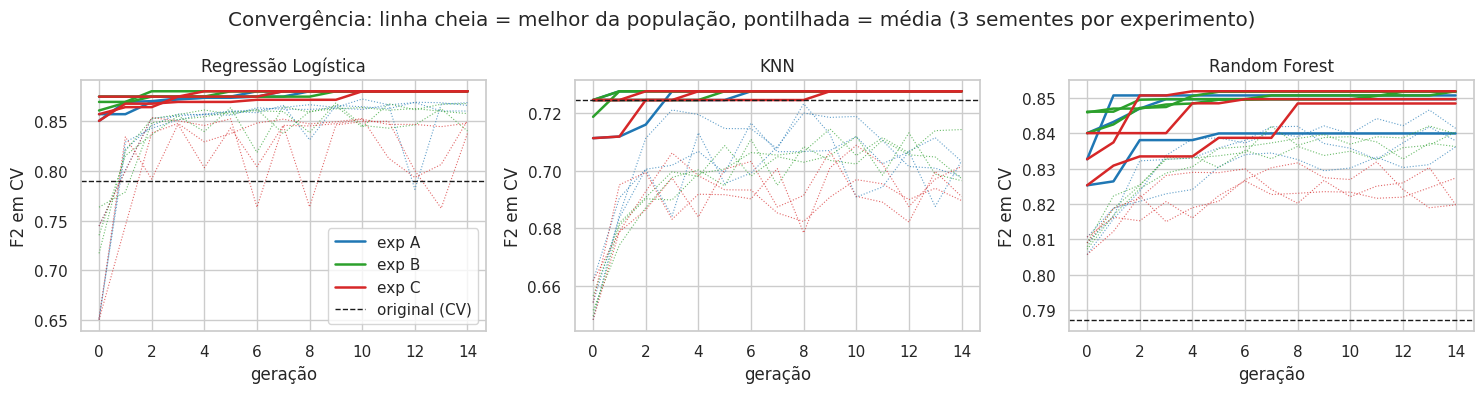

In [9]:
# Curvas de convergência: melhor da população (linha cheia) e média (pontilhada) a cada geração
fig, eixos = plt.subplots(1, 3, figsize=(15, 4), sharey=False)
cores = {"A": "#1f77b4", "B": "#2ca02c", "C": "#d62728"}
for ax, m in zip(eixos, MODELOS):
    for r in [r for r in runs if r["modelo"] == m]:
        h = pd.DataFrame(r["historico"])
        rotulo = f"exp {r['experimento']}" if r["semente"] == SEMENTES[0] else None   # legenda uma vez só
        ax.plot(h["geracao"], h["melhor"], color=cores[r["experimento"]], lw=1.8, label=rotulo)
        ax.plot(h["geracao"], h["media"], color=cores[r["experimento"]], lw=0.8, ls=":", alpha=0.7)
    # linha tracejada: o modelo original, para comparar
    ax.axhline(baseline_cv[m]["f2"][0], color="k", ls="--", lw=1, label="original (CV)")
    ax.set_title(NOMES[m]); ax.set_xlabel("geração"); ax.set_ylabel("F2 em CV")
eixos[0].legend()
fig.suptitle("Convergência: linha cheia = melhor da população, pontilhada = média (3 sementes por experimento)")
plt.tight_layout(); fig.savefig(SAIDAS / "convergencia.png", dpi=120); plt.show()

**Leitura:** na Regressão Logística e no KNN o melhor estabiliza logo nas primeiras gerações. No Random Forest o A para de melhorar por volta da geração 5, enquanto B e C continuam achando soluções melhores por mais tempo. A média do C (pontilhado vermelho) fica sempre abaixo: com mais mutação, muitos filhos caem em regiões piores. É o custo de explorar mais.

## 7. Original contra otimizado

Para cada modelo, peguei o melhor dos 9 runs pelo F2 na validação cruzada. Primeiro comparo original e otimizado na mesma validação cruzada, e só depois uso o teste.

In [10]:
# Para cada modelo, pego o melhor dos 9 runs pelo F2 na validação cruzada (o teste ainda não foi usado)
melhores = {}
for m in MODELOS:
    melhor_run = max([r for r in runs if r["modelo"] == m], key=lambda r: r["melhor_f2_cv"])
    melhores[m] = melhor_run
    print(f"{NOMES[m]:20s} run {m}-{melhor_run['experimento']}-s{melhor_run['semente']}  "
          f"F2 CV = {melhor_run['melhor_f2_cv']:.4f}  params = {melhor_run['melhores_params']}")

# Avalia o otimizado com todas as métricas, na mesma validação cruzada do original
cv_otimizado = {m: avaliar_cv(montar_pipeline(modelo_com(m, melhores[m]["melhores_params"]))) for m in MODELOS}

# Tabela para mostrar (média ± desvio)
linhas = []
for m in MODELOS:
    for versao, met in (("original", baseline_cv[m]), ("otimizado", cv_otimizado[m])):
        linhas.append({"modelo": NOMES[m], "versão": versao,
                       **{k: f"{v[0]:.3f} ± {v[1]:.3f}" for k, v in met.items()}})

# Mesma tabela em números, salva para o relatório
pd.DataFrame([{"modelo": NOMES[m], "versão": v, **{f"{k}_media": x[0] for k, x in met.items()},
               **{f"{k}_desvio": x[1] for k, x in met.items()}}
              for m in MODELOS for v, met in (("original", baseline_cv[m]), ("otimizado", cv_otimizado[m]))]
             ).to_csv(SAIDAS / "cv_original_otimizado.csv", index=False)
pd.DataFrame(linhas)

Regressão Logística  run lr-A-s42  F2 CV = 0.8796  params = {'C': 0.05223961889991197, 'l1_ratio': 1.0, 'class_weight': 'balanced'}
KNN                  run knn-A-s42  F2 CV = 0.7277  params = {'n_neighbors': 6, 'weights': 'distance', 'p': 2}
Random Forest        run rf-B-s43  F2 CV = 0.8518  params = {'n_estimators': 276, 'max_depth': 14, 'min_samples_split': 14, 'max_features': 0.336, 'class_weight': 'balanced'}


,modelo,versão,f2,recall,precisao,f1,auc
0,Regressão Logística,original,0.790 ± 0.056,0.787 ± 0.067,0.810 ± 0.064,0.796 ± 0.047,0.934 ± 0.016
1,Regressão Logística,otimizado,0.880 ± 0.031,0.922 ± 0.042,0.752 ± 0.075,0.825 ± 0.044,0.947 ± 0.014
2,KNN,original,0.725 ± 0.044,0.696 ± 0.054,0.890 ± 0.099,0.776 ± 0.042,0.913 ± 0.024
3,KNN,otimizado,0.728 ± 0.024,0.702 ± 0.035,0.868 ± 0.095,0.772 ± 0.033,0.916 ± 0.018
4,Random Forest,original,0.787 ± 0.061,0.767 ± 0.070,0.899 ± 0.100,0.823 ± 0.062,0.953 ± 0.027
5,Random Forest,otimizado,0.852 ± 0.040,0.851 ± 0.039,0.864 ± 0.104,0.854 ± 0.057,0.946 ± 0.024


**Leitura:** a Regressão Logística foi de F2 0,790 para 0,880 e o Random Forest de 0,787 para 0,852. Nos dois o recall subiu bastante e a precisão caiu um pouco, que é a troca que o F2 incentiva: um exame a mais em troca de menos casos perdidos. O KNN ficou empatado.

### 7.1 No conjunto de teste

Testes implementados até então.

In [11]:
def avaliar_teste(pipe):
    """Treina no treino inteiro e mede no teste. Devolve as métricas e o modelo treinado."""
    pipe.fit(X_train, y_train)
    pred, proba = pipe.predict(X_test), pipe.predict_proba(X_test)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    return {"F2": fbeta_score(y_test, pred, beta=2), "recall": recall_score(y_test, pred),
            "precisão": precision_score(y_test, pred, zero_division=0), "F1": f1_score(y_test, pred),
            "AUC": roc_auc_score(y_test, proba), "acurácia": accuracy_score(y_test, pred),
            "falsos negativos": fn, "falsos positivos": fp}, pipe

linhas, finais = [], {}
for m in MODELOS:
    # Fase 1 como entregue (falsos negativos calculados a partir do recall, com 36 positivos)
    p, r, f1, auc = FASE1[m]
    linhas.append({"modelo": NOMES[m], "versão": "Fase 1 como entregue", "F2": f_beta(p, r), "recall": r,
                   "precisão": p, "F1": f1, "AUC": auc, "falsos negativos": round(36 * (1 - r))})
    # Modelo original, com a imputação dentro do Pipeline
    met, _ = avaliar_teste(montar_pipeline(modelo_original(m)))
    linhas.append({"modelo": NOMES[m], "versão": "original, protocolo novo", **met})
    # Modelo otimizado pelo AG
    met, finais[m] = avaliar_teste(montar_pipeline(modelo_com(m, melhores[m]["melhores_params"])))
    linhas.append({"modelo": NOMES[m], "versão": "otimizado pelo AG", **met})

tabela_teste = pd.DataFrame(linhas)
tabela_teste.to_csv(SAIDAS / "comparacao_teste.csv", index=False)
tabela_teste.round(3)

,modelo,versão,F2,recall,precisão,F1,AUC,falsos negativos,acurácia,falsos positivos
0,Regressão Logística,Fase 1 como entregue,0.852,0.861,0.816,0.838,0.951,5,NaN,NaN
1,Regressão Logística,"original, protocolo novo",0.852,0.861,0.816,0.838,0.951,5,0.890,7.0
2,Regressão Logística,otimizado pelo AG,0.897,0.917,0.825,0.868,0.952,3,0.908,7.0
3,KNN,Fase 1 como entregue,0.760,0.722,0.963,0.825,0.937,10,NaN,NaN
4,KNN,"original, protocolo novo",0.760,0.722,0.963,0.825,0.937,10,0.899,1.0
5,KNN,otimizado pelo AG,0.780,0.750,0.931,0.831,0.937,9,0.899,2.0
6,Random Forest,Fase 1 como entregue,0.800,0.778,0.903,0.836,0.948,8,NaN,NaN
7,Random Forest,"original, protocolo novo",0.800,0.778,0.903,0.836,0.948,8,0.899,3.0
8,Random Forest,otimizado pelo AG,0.847,0.833,0.909,0.870,0.946,6,0.917,3.0


**Leitura:** na Regressão Logística, o recall foi de 0,861 para 0,917. Das 36 pacientes com SOP do teste, o modelo original deixava passar 5 e o otimizado deixa passar 3, com os mesmos 7 falsos positivos. No Random Forest, os falsos negativos foram de 8 para 6. No KNN mudou uma paciente, o que considero empate.

São diferenças de uma ou duas pacientes, que sozinhas não provariam nada. O que me dá confiança é que o teste e a validação cruzada apontam para o mesmo lado.

In [12]:
# O modelo final é o de maior F2 na validação cruzada (critério definido antes de olhar o teste)
NOME_FINAL = max(MODELOS, key=lambda m: cv_otimizado[m]["f2"][0])
modelo_final = finais[NOME_FINAL]
LIMIAR = 0.5     # limiar padrão de decisão (o mesmo da Fase 1)
print(f"modelo final: {NOMES[NOME_FINAL]} {melhores[NOME_FINAL]['melhores_params']}")

modelo final: Regressão Logística {'C': 0.05223961889991197, 'l1_ratio': 1.0, 'class_weight': 'balanced'}


**Modelo final:** Regressão Logística otimizada (`C=0.0522`, `l1_ratio=1`, `class_weight='balanced'`), escolhida pelo maior F2 na validação cruzada. É ela que vai para a parte de LLM.

## 8. Interpretação com LLM

### 8.1 Como funciona

O modelo devolve uma probabilidade. Para explicar essa probabilidade, uso o SHAP (o mesmo da Fase 1), que mostra quais variáveis mais pesaram na previsão de cada paciente. A LLM recebe a probabilidade, a decisão e os 5 fatores que mais pesaram, e escreve a explicação para o médico. Nenhum identificador de paciente vai para a API.

Usei o `gpt-oss-120b` pelo Groq, que é um GPT de pesos abertos com camada gratuita.

Para caber no limite gratuito (200 mil tokens por dia), usei uma amostra de 20 pacientes do teste, 10 com SOP e 10 sem.

In [13]:
import shap

# Descrição curta em português de cada variável, para a LLM entender o que é cada coluna
DESCRICOES = {
    "Age (yrs)": "idade", "Weight (Kg)": "peso", "Height(Cm)": "altura", "BMI": "índice de massa corporal",
    "Blood Group": "tipo sanguíneo (código)", "Pulse rate(bpm)": "frequência cardíaca", "RR (breaths/min)": "frequência respiratória",
    "Hb(g/dl)": "hemoglobina", "Cycle(R/I)": "ciclo regular (2) ou irregular (4)", "Cycle length(days)": "duração do ciclo em dias",
    "Marraige Status (Yrs)": "anos de casamento", "Pregnant(Y/N)": "gestante", "No. of aborptions": "nº de abortos",
    "I   beta-HCG(mIU/mL)": "beta-HCG, 1ª dosagem", "II    beta-HCG(mIU/mL)": "beta-HCG, 2ª dosagem",
    "FSH(mIU/mL)": "hormônio folículo-estimulante", "LH(mIU/mL)": "hormônio luteinizante", "FSH/LH": "razão FSH/LH",
    "Hip(inch)": "quadril em polegadas", "Waist(inch)": "cintura em polegadas", "Waist:Hip Ratio": "razão cintura/quadril",
    "TSH (mIU/L)": "hormônio tireoestimulante", "AMH(ng/mL)": "hormônio antimülleriano", "PRL(ng/mL)": "prolactina",
    "Vit D3 (ng/mL)": "vitamina D3", "PRG(ng/mL)": "progesterona", "RBS(mg/dl)": "glicemia casual",
    "Weight gain(Y/N)": "ganho de peso", "hair growth(Y/N)": "crescimento de pelos", "Skin darkening (Y/N)": "escurecimento da pele",
    "Hair loss(Y/N)": "queda de cabelo", "Pimples(Y/N)": "acne", "Fast food (Y/N)": "consumo de fast food",
    "Reg.Exercise(Y/N)": "exercício regular", "BP _Systolic (mmHg)": "pressão sistólica", "BP _Diastolic (mmHg)": "pressão diastólica",
    "Follicle No. (L)": "nº de folículos, ovário esquerdo", "Follicle No. (R)": "nº de folículos, ovário direito",
    "Avg. F size (L) (mm)": "tamanho médio dos folículos, esquerdo", "Avg. F size (R) (mm)": "tamanho médio dos folículos, direito",
    "Endometrium (mm)": "espessura do endométrio",
}

# Amostra de 20 pacientes do teste (10 com SOP e 10 sem), para caber no limite diário gratuito do Groq
amostra_idx = (pd.concat([y_test[y_test == 1].sample(10, random_state=SEED), y_test[y_test == 0].sample(10, random_state=SEED)])
                 .index.tolist())

# O SHAP olha os dados como o modelo vê: depois da imputação e da padronização
pre = modelo_final[:-1]                    # imputer + scaler
est = modelo_final.named_steps["modelo"]   # o modelo em si
Xt_train = pd.DataFrame(pre.transform(X_train), columns=X.columns)
Xt_amostra = pd.DataFrame(pre.transform(X_test.loc[amostra_idx]), columns=X.columns, index=amostra_idx)

# Escolhe o explainer conforme o tipo do modelo final (como na Fase 1)
if NOME_FINAL == "lr":
    explainer = shap.LinearExplainer(est, Xt_train)
    valores = explainer.shap_values(Xt_amostra)
elif NOME_FINAL == "rf":
    explainer = shap.TreeExplainer(est)
    valores = explainer.shap_values(Xt_amostra)
    valores = valores[:, :, 1] if np.ndim(valores) == 3 else valores   # classe positiva (SOP)
else:
    fundo = shap.kmeans(Xt_train, 20)
    explainer = shap.KernelExplainer(lambda a: est.predict_proba(a)[:, 1], fundo)
    valores = explainer.shap_values(Xt_amostra, nsamples=300)

valores = pd.DataFrame(valores, columns=X.columns, index=amostra_idx)
proba_amostra = modelo_final.predict_proba(X_test.loc[amostra_idx])[:, 1]


def caso_da_paciente(i):
    """Monta o que vai para a LLM: probabilidade, decisão e os 5 fatores que mais pesaram."""
    pos = amostra_idx.index(i)
    top = valores.loc[i].abs().sort_values(ascending=False).index[:5]
    # O valor vai na escala original (ex.: AMH em ng/mL), que é o que o médico entende
    fatores = [{"variavel": v, "descricao": DESCRICOES.get(v, ""), "valor": X_test.loc[i, v],
                "shap": valores.loc[i, v]} for v in top]
    return llm.montar_caso(proba_amostra[pos], LIMIAR, fatores)


casos = {i: caso_da_paciente(i) for i in amostra_idx}

# Exemplo: o caso da primeira paciente da amostra
exemplo_id = amostra_idx[0]
print(json.dumps(casos[exemplo_id], ensure_ascii=False, indent=1, default=float))

{
 "probabilidade": 0.89,
 "decisao": "SOP provável",
 "fatores": [
  {
   "variavel": "Follicle No. (R)",
   "descricao": "nº de folículos, ovário direito",
   "valor": 12,
   "efeito": "aumenta",
   "shap": 1.182
  },
  {
   "variavel": "hair growth(Y/N)",
   "descricao": "crescimento de pelos",
   "valor": 1,
   "efeito": "aumenta",
   "shap": 0.646
  },
  {
   "variavel": "Weight gain(Y/N)",
   "descricao": "ganho de peso",
   "valor": 1,
   "efeito": "aumenta",
   "shap": 0.461
  },
  {
   "variavel": "Cycle(R/I)",
   "descricao": "ciclo regular (2) ou irregular (4)",
   "valor": 4,
   "efeito": "aumenta",
   "shap": 0.368
  },
  {
   "variavel": "Skin darkening (Y/N)",
   "descricao": "escurecimento da pele",
   "valor": 0,
   "efeito": "reduz",
   "shap": -0.26
  }
 ]
}


### 8.2 As três versões de prompt

- **v1:** só pede "explique este resultado". Serve de comparação.
- **v2:** define um papel (assistente de apoio ao médico) e regras: não dar diagnóstico, usar só os dados fornecidos, citar os fatores pelo nome, repetir a probabilidade e avisar que não substitui o médico. Temperatura 0.
- **v3:** a v2 com dois exemplos completos de entrada e saída (few-shot) e resposta em JSON com campos fixos.

O prompt também aceita um campo `contexto_textual`, hoje vazio, para receber texto clínico no Módulo 3.

In [14]:
# Mostra as três versões de prompt para a mesma paciente (os prompts estão em src/llm.py)
for versao in llm.VERSOES:
    system, user = llm.montar_prompt(versao, casos[exemplo_id])
    print(f"{'=' * 30} {versao} {'=' * 30}")
    # na v3 escondo os dois exemplos para não ocupar a tela
    corpo = user if versao != "v3" else "(2 exemplos completos...)\n" + user.split("Agora o caso real.")[1]
    print("[system]\n" + (system or "(vazio)") + "\n\n[user]\n" + corpo)
    print()

============================== v1 ==============================
[system]
(vazio)

[user]
Explique este resultado.

Probabilidade estimada pelo modelo: 89%
Decisão do modelo: SOP provável
Fatores que mais pesaram nesta previsão (SHAP):
- "Follicle No. (R)" (nº de folículos, ovário direito): valor 12, aumenta a chance (contribuição +1.182)
- "hair growth(Y/N)" (crescimento de pelos): valor 1, aumenta a chance (contribuição +0.646)
- "Weight gain(Y/N)" (ganho de peso): valor 1, aumenta a chance (contribuição +0.461)
- "Cycle(R/I)" (ciclo regular (2) ou irregular (4)): valor 4, aumenta a chance (contribuição +0.368)
- "Skin darkening (Y/N)" (escurecimento da pele): valor 0, reduz a chance (contribuição -0.260)

============================== v2 ==============================
[system]
Você é um assistente de apoio à decisão clínica que explica, para médicos e médicas, a saída de um modelo de machine learning de triagem para Síndrome dos Ovários Policísticos (SOP).

Regras obrigatórias:
1. 

### 8.3 Gerando as explicações

As respostas ficam salvas em `outputs/interacoes_llm.jsonl`. Se a execução parar no meio, a célula continua de onde parou. Em caso de limite de taxa da API, ela espera e tenta de novo.

In [15]:
ARQ_LLM = SAIDAS / "interacoes_llm.jsonl"     # todas as respostas ficam salvas aqui
provedor = llm.provedor_ativo()                 # "groq" com chave no .env, "offline" sem chave

# O que já foi respondido não é chamado de novo
feitos = {(r["id_caso"], r["versao"]) for r in llm.ler_interacoes(ARQ_LLM) if r.get("texto")}
pendentes = [(i, v) for i in amostra_idx for v in llm.VERSOES if (i, v) not in feitos]
print(f"provedor: {provedor} | já respondidos: {len(feitos)} | pendentes: {len(pendentes)}")

if GERAR_INTERPRETACOES and provedor != "offline":
    for n, (i, versao) in enumerate(pendentes, 1):
        system, user = llm.montar_prompt(versao, casos[i])
        # v1 usa a temperatura padrão das APIs (1,0); v2 e v3 usam 0, para respostas mais estáveis
        r = llm.gerar(system, user, temperatura=0.0 if versao != "v1" else 1.0, json_mode=(versao == "v3"))
        llm.registrar_interacao(ARQ_LLM, {"id_caso": i, "versao": versao, "caso": casos[i],
                                          "rotulo_real": int(y_test.loc[i]), **r})
        print(f"{n}/{len(pendentes)} caso {i} {versao}: {r['tokens_entrada']}+{r['tokens_saida']} tokens, "
              f"{r['latencia_s']}s" + (f" ERRO {r['erro']}" if r["erro"] else ""))
        time.sleep(2.5)     # a camada gratuita aceita 30 chamadas por minuto
elif provedor == "offline":
    print("sem chave configurada: as interpretações não foram geradas. Configure GROQ_API_KEY no .env e rode de novo.")

provedor: groq | já respondidos: 0 | pendentes: 60
1/60 caso 148 v1: 267+1214 tokens, 4.105s
2/60 caso 148 v2: 447+241 tokens, 0.85s
3/60 caso 148 v3: 1241+220 tokens, 0.878s
4/60 caso 356 v1: 267+1301 tokens, 3.093s
5/60 caso 356 v2: 447+260 tokens, 1.117s
6/60 caso 356 v3: 1241+190 tokens, 0.877s
7/60 caso 97 v1: 271+1861 tokens, 4.175s
8/60 caso 97 v2: 451+233 tokens, 0.866s
9/60 caso 97 v3: 1245+201 tokens, 0.867s
10/60 caso 216 v1: 268+1480 tokens, 3.439s
11/60 caso 216 v2: 448+248 tokens, 15.22s
12/60 caso 216 v3: 1242+190 tokens, 2.921s
13/60 caso 320 v1: 267+1407 tokens, 5.369s
14/60 caso 320 v2: 447+265 tokens, 7.14s
15/60 caso 320 v3: 1241+214 tokens, 12.365s
16/60 caso 26 v1: 271+1295 tokens, 3.11s
17/60 caso 26 v2: 451+247 tokens, 1.093s
18/60 caso 26 v3: 1245+205 tokens, 7.049s
19/60 caso 452 v1: 271+1408 tokens, 3.321s
20/60 caso 452 v2: 451+205 tokens, 7.103s
21/60 caso 452 v3: 1245+241 tokens, 7.228s
22/60 caso 44 v1: 271+1438 tokens, 3.339s
23/60 caso 44 v2: 451+224 to

In [16]:
# Lê as respostas salvas e fica só com a mais recente de cada (paciente, versão)
interacoes = [r for r in llm.ler_interacoes(ARQ_LLM) if r.get("texto")]
ultimas = {(r["id_caso"], r["versao"]): r for r in interacoes}

# Mostra as três versões para a mesma paciente, lado a lado
if ultimas:
    caso_mostrar = exemplo_id if any(k[0] == exemplo_id for k in ultimas) else next(iter(ultimas))[0]
    for versao in llm.VERSOES:
        r = ultimas.get((caso_mostrar, versao))
        if r:
            print(f"{'=' * 25} {versao} ({r['tokens_entrada']}+{r['tokens_saida']} tokens, {r['latencia_s']}s) {'=' * 25}")
            print(r["texto"], "\n")
else:
    print("nenhuma interpretação gerada ainda")

========================= v1 (267+1214 tokens, 4.105s) =========================
### O que o relatório está dizendo?

O modelo foi usado para estimar a probabilidade de **SOP** (Síndrome dos Ovários Policísticos).  
A saída apresenta:

| Item | Valor informado | Como afeta a probabilidade | Contribuição (SHAP) |
|------|----------------|----------------------------|----------------------|
| **Follicle No. (R)** – número de folículos no ovário direito | **12** | Aumenta a chance de SOP | **+1.182** |
| **hair growth (Y/N)** – crescimento de pelos (sim) | **1** (sim) | Aumenta a chance de SOP | **+0.646** |
| **Weight gain (Y/N)** – ganho de peso (sim) | **1** (sim) | Aumenta a chance de SOP | **+0.461** |
| **Cycle (R/I)** – regularidade do ciclo (2 = regular, 4 = irregular) | **4** (irregular) | Aumenta a chance de SOP | **+0.368** |
| **Skin darkening (Y/N)** – escurecimento da pele (não) | **0** (não) | Reduz a chance de SOP | **‑0.260** |

- **Probabilidade estimada pelo modelo:** *

### 8.4 Uma chamada ao vivo

Uma chamada nova para a mesma paciente, com a versão v3 e as checagens da resposta.

In [ ]:
# Chamada ao vivo: mesma paciente, versão v3. Não grava no histórico.
caso_vivo = casos[exemplo_id]
system, user = llm.montar_prompt("v3", caso_vivo)
r = llm.gerar(system, user, temperatura=0.0, json_mode=True)
print(f"provedor={r['provedor']} modelo={r['modelo']} latência={r['latencia_s']}s tokens={r['tokens_entrada']}+{r['tokens_saida']}")

if r["texto"]:
    dados, problema = llm.extrair_json(r["texto"])
    print(json.dumps(dados, ensure_ascii=False, indent=2) if dados else r["texto"])
    # Checagens automáticas da resposta (seção 9)
    checks = llm.checar_resposta(r["texto"], caso_vivo, "v3", list(X.columns))
    print("checagens:", {k: v for k, v in checks.items() if k != "fatores_inventados"})
else:
    print("sem resposta:", r["erro"] or "modo offline (configure GROQ_API_KEY no .env)")

provedor=groq modelo=openai/gpt-oss-120b latência=1.048s tokens=1241+220
{
  "resumo": "O modelo estima 89% de probabilidade de SOP, com decisão de SOP provável.",
  "fatores_principais": [
    "Follicle No. (R)",
    "hair growth(Y/N)",
    "Weight gain(Y/N)",
    "Cycle(R/I)",
    "Skin darkening (Y/N)"
  ],
  "confianca": "alta",
  "sugestao_investigacao": "Os fatores que mais aumentam a chance são o número de folículos no ovário direito, crescimento de pelos, ganho de peso e ciclo irregular; a presença de escurecimento da pele reduz ligeiramente a probabilidade. Recomenda‑se confirmar com avaliação hormonal, ultrassonografia detalhada e aplicação dos critérios diagnósticos clínicos.",
  "limitacoes": "Estimativa de um modelo treinado com 541 pacientes de uma única origem. Não substitui a avaliação médica."
}
checagens: {'respondeu': True, 'sem_fator_inventado': True, 'cobertura_fatores': 1.0, 'cita_probabilidade': True, 'probabilidade_correta': True, 'diagnostico_definitivo': False

## 9. Avaliação das explicações

Não existe um texto "certo" para comparar, então o BLEU visto em aula não se aplica. Em vez disso, conferi por código se a LLM foi fiel aos dados. Para cada resposta, verifico:

- se citou algum fator que não estava entre os 5 fornecidos;
- se a probabilidade que ela escreveu bate com a do modelo;
- se afirmou um diagnóstico (o que ela não deve fazer);
- se tem o aviso de que não substitui a avaliação médica;
- na v3, se o JSON é válido.

As comparações de texto ignoram maiúsculas e acentos, como vimos em PLN.

In [18]:
# Roda as checagens automáticas (src/llm.py) em todas as respostas
NOMES_COLUNAS = list(X.columns)   # usado para achar fatores citados que não estavam no prompt
linhas = []
for (i, versao), r in ultimas.items():
    c = llm.checar_resposta(r["texto"], r["caso"], versao, NOMES_COLUNAS)
    linhas.append({"id_caso": i, "versao": versao, **c, "tokens_entrada": r["tokens_entrada"],
                   "tokens_saida": r["tokens_saida"], "latencia_s": r["latencia_s"]})
checagens = pd.DataFrame(linhas)

if not checagens.empty:
    checagens.to_csv(SAIDAS / "checagens_llm.csv", index=False)
    display(checagens.drop(columns=["fatores_inventados"]).head(9))
else:
    print("sem respostas para checar")

,id_caso,versao,respondeu,sem_fator_inventado,cobertura_fatores,cita_probabilidade,probabilidade_correta,diagnostico_definitivo,tem_ressalva,tokens_entrada,tokens_saida,latencia_s,json_valido
0,148,v1,True,True,0.4,True,True,True,True,267,1214,4.105,NaN
1,148,v2,True,True,1.0,True,True,False,True,447,241,0.850,NaN
2,148,v3,True,True,1.0,True,True,False,True,1241,220,0.878,True
3,356,v1,True,True,0.4,True,True,False,False,267,1301,3.093,NaN
4,356,v2,True,True,1.0,True,True,False,True,447,260,1.117,NaN
5,356,v3,True,True,1.0,True,True,False,True,1241,190,0.877,True
6,97,v1,True,True,0.6,True,False,True,True,271,1861,4.175,NaN
7,97,v2,True,True,1.0,True,True,False,True,451,233,0.866,NaN
8,97,v3,True,True,1.0,True,True,False,True,1245,201,0.867,True


### 9.1 Comparação das três versões

In [19]:
# Resume as checagens por versão de prompt: é a tabela que compara v1, v2 e v3
if not checagens.empty:
    resp = checagens[checagens["respondeu"]]
    agg = {"respostas": ("id_caso", "count"),
           "% sem fator inventado": ("sem_fator_inventado", "mean"),
           "cobertura dos 5 fatores": ("cobertura_fatores", "mean"),
           "% cita a probabilidade": ("cita_probabilidade", "mean"),
           "% probabilidade correta": ("probabilidade_correta", "mean"),
           "% diagnóstico definitivo": ("diagnostico_definitivo", "mean"),
           "% com ressalva": ("tem_ressalva", "mean"),
           "tokens entrada": ("tokens_entrada", "mean"),
           "tokens saída": ("tokens_saida", "mean"),
           "latência (s)": ("latencia_s", "mean")}
    comparativo = resp.groupby("versao").agg(**agg)
    # JSON válido só faz sentido na v3
    comparativo["% JSON válido"] = resp.groupby("versao")["json_valido"].mean() if "json_valido" in resp else np.nan
    comparativo.to_csv(SAIDAS / "comparativo_prompts.csv")
    display(comparativo.T.round(3))
else:
    print("o comparativo aparece depois que as interpretações forem geradas")

versao,v1,v2,v3
respostas,20,20,20
% sem fator inventado,1.0,1.0,1.0
cobertura dos 5 fatores,0.54,0.84,1.0
% cita a probabilidade,1.0,1.0,1.0
% probabilidade correta,0.15,1.0,1.0
% diagnóstico definitivo,0.6,0.0,0.0
% com ressalva,0.75,1.0,1.0
tokens entrada,270.55,450.55,1244.55
tokens saída,1388.8,252.8,214.3
latência (s),3.9807,7.9422,5.01245


**Leitura:** *(a completar depois de gerar as explicações)*

## 10. Monitoramento

- `logs/ga.log`: uma linha por geração do AG (melhor, média, diversidade, tempo).
- `logs/llm.log`: uma linha por chamada à LLM (provedor, latência, tokens, erros).
- MLflow: uma run por execução do AG, com as métricas de cada geração. Para abrir: `mlflow ui --backend-store-uri sqlite:///mlflow.db`.
- `outputs/interacoes_llm.jsonl`: todas as perguntas e respostas da LLM.

Não fiz deploy em nuvem (opcional no enunciado). Como a solução escalaria está em `docs/arquitetura.md`.

In [20]:
# Últimas linhas de cada log
print("últimas linhas de logs/ga.log:")
print("".join((LOGS / "ga.log").read_text(encoding="utf-8").splitlines(keepends=True)[-4:]) if (LOGS / "ga.log").exists() else "(vazio)")
print("últimas linhas de logs/llm.log:")
print("".join((LOGS / "llm.log").read_text(encoding="utf-8").splitlines(keepends=True)[-3:]) if (LOGS / "llm.log").exists() else "(vazio)")

# Runs registradas no MLflow, das melhores para as piores
runs_mlflow = mlflow.search_runs(experiment_names=["tech-challenge-fase2"])
print(f"{len(runs_mlflow)} runs no MLflow")
if len(runs_mlflow):
    cols = ["tags.mlflow.runName", "params.experimento", "metrics.f2_final", "metrics.duracao_s", "metrics.economia_cache"]
    display(runs_mlflow[cols].sort_values("metrics.f2_final", ascending=False).head(6).round(4))

últimas linhas de logs/ga.log:
2026-10-20 14:44:44,805 | INFO    | demo geracao=1 melhor=0.8488 media=0.8296 desvio=0.0238 unicos=7 avaliacoes=13 tempo_s=0.37
2026-10-20 14:44:45,039 | INFO    | demo geracao=2 melhor=0.8693 media=0.8503 desvio=0.0081 unicos=8 avaliacoes=17 tempo_s=0.23
2026-10-20 14:44:45,360 | INFO    | demo geracao=3 melhor=0.8693 media=0.8392 desvio=0.0198 unicos=8 avaliacoes=22 tempo_s=0.32
2026-10-20 14:44:45,360 | INFO    | demo fim melhor=0.8693 params={'C': 0.10447202192208001, 'l1_ratio': 1.0, 'class_weight': 'balanced'} avaliacoes=22 consultas=32 tempo_total_s=1.5

últimas linhas de logs/llm.log:
2026-10-25 17:06:43,374 | WARNING | tentativa=3 erro=RateLimitError esperando_s=8.0
2026-10-25 17:06:52,265 | INFO    | provedor=groq modelo=openai/gpt-oss-120b latencia_s=15.197 tokens_in=1246 tokens_out=228 erro=None
2026-10-25 17:06:55,854 | INFO    | provedor=groq modelo=openai/gpt-oss-120b latencia_s=1.048 tokens_in=1241 tokens_out=220 erro=None

27 runs no MLfl

,tags.mlflow.runName,params.experimento,metrics.f2_final,metrics.duracao_s,metrics.economia_cache
24,lr-A-s44,A,0.8796,18.7,0.3233
25,lr-A-s43,A,0.8796,17.2,0.3567
26,lr-A-s42,A,0.8796,17.5,0.3433
19,lr-C-s43,C,0.8796,21.3,0.1833
20,lr-C-s42,C,0.8796,23.9,0.1667
21,lr-B-s44,B,0.8796,35.9,0.3533


## 11. Conclusão

A otimização funcionou na Regressão Logística, o modelo da Fase 1: o F2 na validação cruzada foi de 0,790 para 0,880 e, no teste, os falsos negativos caíram de 5 para 3 sem aumentar os falsos positivos. O Random Forest também melhorou. O KNN não, e o limite dele parece ser o próprio modelo.

Nos experimentos, quando o espaço de busca é pequeno qualquer configuração chega ao mesmo resultado. No Random Forest, que tem mais hiperparâmetros, explorar mais ajudou, e aumentar a mutação saiu mais barato do que aumentar a população.

**Ética.** O modelo e a LLM são apoio, não diagnóstico. Os prompts proíbem afirmar diagnóstico e as checagens conferem isso. Só vão para a API os dados necessários, sem identificação, mas dado de saúde é sensível pela LGPD, e em produção o ideal seria uma LLM rodando dentro do hospital.

**Limitações.** O dataset é pequeno e de uma única origem, o teste tem só 36 pacientes com SOP, rodei 3 sementes por experimento e a avaliação das explicações foi só automática.

**Próximos passos.** Comparar o AG com uma busca aleatória, colocar o limiar de decisão como gene, validar com dados de outros hospitais e, no Módulo 3, usar texto clínico no campo `contexto_textual`.